In [13]:
import os; 
if os.getcwd().endswith("notebooks"):
    os.chdir("../..")  # run from repo root

In [14]:
import sys
import importlib
import numpy as np
from IPython.display import display, Markdown
from qiskit import QuantumCircuit, qasm2
from qiskit.converters import circuit_to_dag
from resource_estimator.codes import Concatenated422Code, SurfaceCode, \
SurfaceCodePartialFaultTolerant, SurfaceCodePartialFaultTolerantErrorCorrectionStyle, \
CSDCode, HybridHelixSurfaceCode, SurfaceCodeErrorCorrectionStyle, CSDErrorCorrectionStyle, CSDResourceState
from resource_estimator.codes import ColorCode, ColorCodeInstruction, ColorCodeResourceState, ColorCodeErrorCorrectionStyle
from resource_estimator.comp_utils import expand_qiskit_circuit, transpile_qiskit_circuit
from resource_estimator.plotting import (
    plot_allocation_profiles_errorbar,
    plot_allocation_profiles_stacked_bar,
    plot_instruction_profiles_errorbar,
    plot_instruction_profiles_stacked_bar,
    plot_resource_demand_errorbar,
    plot_resource_demand_stacked_bar,
    plot_dag_progress,
)
from resource_estimator.tests.helpers import run_schedule_for_code
from circuits import tfim_trotter_2dsquare
import warnings
import matplotlib.pyplot as plt

In [15]:
# Select one input file; no circuit optimization is applied when loading it.
from collections import Counter
import json
import pickle
from pathlib import Path

from pytket import Circuit
from pytket.extensions.qiskit import tk_to_qiskit
from resource_estimator.circuit_adapter import prepare_circuit_for_retrace

circuit_filename = "phase_z1.json"#   # or "h2_1qubit_qpe_phase_7.pkl"
pickle_circuit_key = "optimized circuit"  # or the separately saved "optimized circuit"
angle_tolerance = 1e-10  # Radians; 0 disables approximate special-angle snapping.

# GridSynth settings for conventional Clifford+T codes.
# Hybrid and surface pFT retain the rotation angles, as in prototype_ising.
synth_accuracy = 1e-3  # Per-rotation synthesis tolerance, not a failure probability
implementation = "python"  # "python": pygridsynth; "qiskit": qiskit-gridsynth-plugin
simplify = True  # Simplify generated Clifford+T sequences; does not optimize the input

input_dir = Path("circuits/chemistry/my_chemistry_circuits")
file_path = input_dir / circuit_filename
if file_path.suffix == ".json":
    with file_path.open() as file:
        tk_circuit = Circuit.from_dict(json.load(file))
    circuit_label = circuit_filename
elif file_path.suffix == ".pkl":
    # This local pickle contains a dictionary of metadata and saved pytket circuits.
    with file_path.open("rb") as file:
        saved = pickle.load(file)
    tk_circuit = saved[pickle_circuit_key]
    circuit_label = f"{circuit_filename} [{pickle_circuit_key}]"
else:
    raise ValueError(f"Unsupported circuit format: {file_path.suffix}")

# Convert the format first, retaining measurements, classical destinations and resets.
qc_input = tk_to_qiskit(tk_circuit, replace_implicit_swaps=True)
input_snapshot = qc_input.copy()
input_counts = dict(qc_input.count_ops())

# Use the shared adapter, preserving supported gates such as CZ and RZZ.
qc = prepare_circuit_for_retrace(tk_circuit, angle_tolerance=angle_tolerance)
assert qc_input == input_snapshot
assert (qc.num_qubits, qc.num_clbits) == (qc_input.num_qubits, qc_input.num_clbits)

# Check that every measurement/reset keeps its quantum and classical arguments.
def nonunitary_operations(circuit):
    return Counter(
        (item.operation.name,
         tuple(circuit.find_bit(q).index for q in item.qubits),
         tuple(circuit.find_bit(c).index for c in item.clbits))
        for item in circuit.data if item.operation.name in {"measure", "reset"}
    )

assert nonunitary_operations(qc) == nonunitary_operations(qc_input)
rotation_counts = {name: qc.count_ops().get(name, 0) for name in ("rx", "ry", "rz", "rzz")}
num_rotations = sum(rotation_counts.values())
num_rotation_gates = num_rotations

print(f"Loaded: {circuit_label}")
print(f"Saved pytket operations: {dict(Counter(cmd.op.type.name for cmd in tk_circuit.get_commands()))}")
print(f"Qiskit input: {len(qc_input.data)} operations; {input_counts}")
print(f"ReTrace rotation basis: {len(qc.data)} operations; {dict(qc.count_ops())}")
print(f"Qubits: {qc.num_qubits}; classical bits: {qc.num_clbits}; depth: {qc.depth()}")
print(f"Rotations in the ReTrace basis: {num_rotations}; by type: {rotation_counts}")
print(f"Measurements: {qc.count_ops().get('measure', 0)}; resets: {qc.count_ops().get('reset', 0)}")
print(f"GridSynth: implementation={implementation}, synth_accuracy={synth_accuracy}, simplify={simplify}")


Loaded: phase_z1.json
Saved pytket operations: {'Rz': 36, 'H': 30, 'CX': 13, 'Measure': 2}
Qiskit input: 81 operations; {'rz': 36, 'h': 30, 'cx': 13, 'measure': 2}
ReTrace rotation basis: 81 operations; {'h': 30, 'rz': 22, 'cx': 13, 's': 9, 'sdg': 4, 'measure': 2, 'z': 1}
Qubits: 2; classical bits: 2; depth: 67
Rotations in the ReTrace basis: 22; by type: {'rx': 0, 'ry': 0, 'rz': 22, 'rzz': 0}
Measurements: 2; resets: 0
GridSynth: implementation=python, synth_accuracy=0.001, simplify=True


Circuit preparation lives in the shared Python module, so other notebooks can use the same implementation:

```python
from resource_estimator.circuit_adapter import prepare_circuit_for_retrace
qc = prepare_circuit_for_retrace(tk_circuit, angle_tolerance=1e-10)
```

The input can be a pytket or Qiskit circuit. The adapter preserves supported gates, including CZ and RZZ, and tracks global phase when decomposing gates and recognizing special rotation angles. Generic R/U gates use the original prototype decompositions.

`angle_tolerance` is an absolute tolerance in radians per recognized angle, not a whole-circuit error budget. Its default is `1e-10`; `0` disables approximate snapping. Measurements, classical destinations, resets and implicit wire permutations are retained. Downstream limitations for resets and qubit reuse after measurement remain unchanged; adaptive classical control is rejected.

For use from another repository, make this ReTrace checkout importable in that notebook's Python environment (for example, install it in editable mode). The function stays in this module; importing the notebook itself is unnecessary.


In [16]:
# Hand the loaded rotation-level circuit to each architecture's compiler.
# Conventional codes apply GridSynth in cell 6; the hybrid retains rotation angles.
qc_dag = circuit_to_dag(qc)
print(f"DAG info: {qc_dag.size()} nodes, depth {qc_dag.depth()}, "
      f"{qc_dag.num_qubits()} quantum bits, {qc_dag.num_clbits()} classical bits")
dict(qc_dag.count_ops())


DAG info: 81 nodes, depth 67, 2 quantum bits, 2 classical bits


{'s': 9, 'sdg': 4, 'h': 30, 'z': 1, 'rz': 22, 'cx': 13, 'measure': 2}

In [25]:
num_samples = 1
seed = 43
num_qubits = 1500
demand_factor = 1
seed_increment = True
parallel_processes = False
allow_jumping = True
perform_ec_on_resource_states = False  # Surface resources in the hybrid model require False
careful_alloc = True
debug = False
space_optimized = True
demand_ramping = True  # Default: True for SurfaceCode/CSDCode, False for Concatenated422Code
warnings.simplefilter('always')

codes = [
        CSDCode(error_correction_default=CSDErrorCorrectionStyle.BSE),
        SurfaceCode(error_correction_default=SurfaceCodeErrorCorrectionStyle.BSE, distance=7),
        ColorCode(error_correction_default=ColorCodeErrorCorrectionStyle.BSE, distance=7),
        #SurfaceCodePartialFaultTolerant(error_correction_default=SurfaceCodePartialFaultTolerantErrorCorrectionStyle.BSE, distance=3),
        HybridHelixSurfaceCode(error_correction_default=CSDErrorCorrectionStyle.BSE),
        #Concatenated422Code(level=3),
        ]

# Keep input measurements; report architectures that cannot compile them.
unsupported_codes = [
    code for code in codes
    if input_counts.get("measure", 0)
    and not any(instruction.is_measurement() for instruction in code.instructions)
]
for code in unsupported_codes:
    print(f"Not run: {code}; measurement instructions are not implemented in this architecture.")
codes = [code for code in codes if code not in unsupported_codes]

# Parallel execution of Scheduler over Codes (no progress bar)
if parallel_processes:
    import concurrent.futures as cf
    from functools import partial

    with cf.ThreadPoolExecutor() as ex:
        schedulers = list(ex.map(
            partial(run_schedule_for_code, qc_dag=qc_dag, num_samples=num_samples, allow_jumping=allow_jumping, perform_ec_on_resource_states=perform_ec_on_resource_states, careful_alloc=careful_alloc, debug=debug, seed=seed, seed_increment=seed_increment, num_qubits=num_qubits, demand_factor=demand_factor, tag="default", params=(), synth_accuracy=synth_accuracy, implementation=implementation, simplify=simplify, space_optimized=space_optimized, demand_ramping=demand_ramping),
            codes
        ))

# Sequential execution of Scheduler over Codes (with progress bar)
else:
    schedulers = []
    for code in codes:
        print(str(code))
        scheduler = run_schedule_for_code(code, qc_dag, num_samples=num_samples, allow_jumping=allow_jumping, perform_ec_on_resource_states=perform_ec_on_resource_states, careful_alloc=careful_alloc, debug=debug, seed=seed, seed_increment=seed_increment, num_qubits=num_qubits, demand_factor=demand_factor, tag="default", params=(), synth_accuracy=synth_accuracy, implementation=implementation, simplify=simplify, space_optimized=space_optimized, demand_ramping=demand_ramping)
        schedulers.append(scheduler)

/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/logical_arch.py:734: UserWarning: LogicalArch: instruction Intrablock_Clifford_Unitary has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.
  warnings.warn(f"{self.__class__.__name__}: instruction {instr} has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.")
/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/logical_arch.py:734: UserWarning: LogicalArch: instruction Teleport_RZ_Plus_State has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.
  warnings.warn(f"{self.__class__.__name__}: instruction {instr} has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instruc

CSDCode ([[20, 2, 6]]) with EC style BSE
Total intrablock Clifford unitaries: 588
Total global S gates from intrablock Cliffords: 1481
QEC DAG ops: {'Prep_Z': 1, 'Global_S': 1481, 'Targeted_T': 500, 'Global_T': 87, 'Targeted_Measure_Z': 1, 'Global_Measure_Z': 1}
Default EC depth: 16, Default EC prep depth: 0
Max non-EC instruction depth by number of code blocks acted upon: {2: 1, 1: 4}
Max depth of any non-EC instruction: 4
Maximum idling time set to: 79
Maximum EC cycles possible within idling cutoff: 5
Minimum QEC cutoff to guarantee EC starts within idling cutoff: 15


100%|██████████| 2071/2071 [00:01<00:00, 1293.58it/s]


SurfaceCode (d = 7) with EC style BSE
QEC DAG ops: {'Prep_Z': 2, 'S': 36, 'H': 722, 'Teleport_Magic_State': 674, 'CNOT': 13, 'Measure_Z': 2}
Default EC depth: 4, Default EC prep depth: 0
Max non-EC instruction depth by number of code blocks acted upon: {1: 1, 2: 1}
Max depth of any non-EC instruction: 1
Maximum idling time set to: 237
Maximum EC cycles possible within idling cutoff: 60
Minimum QEC cutoff to guarantee EC starts within idling cutoff: 1


100%|██████████| 1449/1449 [00:00<00:00, 5060.30it/s]
/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/codes/colorcode.py:167: UserWarning: ColorCode: no color-code idling simulations available; using the surface-code idling crossing point of 237 cycles at distance 7 as an estimate.
  warnings.warn(f"{self.__class__.__name__}: no color-code idling simulations available; using the surface-code idling crossing point of {crossing} cycles at distance {self.__distance} as an estimate.")


ColorCode (d = 7) with EC style BSE
QEC DAG ops: {'Prep_Z': 2, 'S': 36, 'H': 722, 'Teleport_Magic_State': 674, 'CNOT': 13, 'Measure_Z': 2}
Default EC depth: 7, Default EC prep depth: 0
Max non-EC instruction depth by number of code blocks acted upon: {1: 1, 2: 1}
Max depth of any non-EC instruction: 1
Maximum idling time set to: 237
Maximum EC cycles possible within idling cutoff: 34
Minimum QEC cutoff to guarantee EC starts within idling cutoff: 6


100%|██████████| 1449/1449 [00:00<00:00, 4573.49it/s]
/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/logical_arch.py:734: UserWarning: LogicalArch: instruction Intrablock_Clifford_Unitary has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.
  warnings.warn(f"{self.__class__.__name__}: instruction {instr} has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.")
/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/logical_arch.py:734: UserWarning: LogicalArch: instruction Teleport_RZ_Plus_State has ambiguous resource overheads. Skipping this instruction for the purposes of calculating maximum depth of code-block-entangling instructions.
  warnings.warn(f"{self.__class__.__name__}: instruction {instr} has ambiguous resource overheads. Skipping this instruction for the purposes of calc

HybridHelixSurfaceCode ([[20,2,6]] Helix, d=3 surface resources) with EC style BSE
Total intrablock Clifford unitaries: 19
Total global S gates from intrablock Cliffords: 34
QEC DAG ops: {'Prep_Z': 1, 'Global_S': 34, 'Teleport_RZ_Plus_State': 22, 'Targeted_Measure_Z': 1, 'Global_Measure_Z': 1}
Default EC depth: 16, Default EC prep depth: 0
Max non-EC instruction depth by number of code blocks acted upon: {2: 1, 1: 4}
Max depth of any non-EC instruction: 4
Maximum idling time set to: 79
Maximum EC cycles possible within idling cutoff: 5
Minimum QEC cutoff to guarantee EC starts within idling cutoff: 15


100%|██████████| 59/59 [00:00<00:00, 171.44it/s]


In [26]:
# Compare the same selected chemistry circuit and hardware budget across architectures.
# Error is the circuit-level modeled failure probability, without synthesis error.
epsilon_report = 1e-6
ler_synth = 1 - (1 - epsilon_report) ** num_rotations
comparison_rows = [
    "| Architecture | Mean depth ± std | Mean runtime (s) ± std | Peak physical qubits | Circuit logical error ± std | Synthesis error heuristic (ε=10⁻⁶) | Idling limit exceeded |",
    "| --- | ---: | ---: | ---: | ---: | ---: | --- |",
]
architecture_labels = {
    SurfaceCode: "Surface (Clifford+T)",
    SurfaceCodePartialFaultTolerant: "Surface d3 (pFT)",
    HybridHelixSurfaceCode: "Helix + surface d3 (pFT)",
}
for code, scheduler in zip(codes, schedulers):
    result = scheduler.extrusion
    label = architecture_labels.get(type(code), str(code))
    synthesis_error = "—" if isinstance(code, (SurfaceCodePartialFaultTolerant, HybridHelixSurfaceCode)) else f"{ler_synth:.3e}"
    comparison_rows.append(
        f"| {label} | {result.mean_time_step:.2f} ± {result.std_time_step:.2f} "
        f"| {result.mean_real_time:.3f} ± {result.std_real_time:.3f} "
        f"| {result.max_allocated_exact} "
        f"| {result.mean_error_rate:.3e} ± {result.std_error_rate:.3e} "
        f"| {synthesis_error} "
        f"| {'Yes' if any(scheduler.max_idling_time_exceeded) else 'No'} |"
    )
display(Markdown(f"**{circuit_label}; {num_samples} scheduling sample(s); {num_qubits} available physical qubits.**"))
display(Markdown("\n".join(comparison_rows)))
display(Markdown(
    "The synthesis heuristic uses a fixed reporting epsilon of `1e-6`, independent "
    "of the actual synthesis settings, and counts the input Rx/Ry/Rz/RZZ rotations. "
    "It is not added to the circuit logical error; pFT and hybrid rows show —."
))
if num_samples == 1:
    display(Markdown("One sample gives no estimate of run-to-run variation; increase `num_samples` for a statistical comparison."))


**phase_z1.json; 1 scheduling sample(s); 1500 available physical qubits.**

| Architecture | Mean depth ± std | Mean runtime (s) ± std | Peak physical qubits | Circuit logical error ± std | Synthesis error heuristic (ε=10⁻⁶) | Idling limit exceeded |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| CSDCode ([[20, 2, 6]]) with EC style BSE | 52953.00 ± 0.00 | 1588.590 ± 0.000 | 282 | 8.112e-05 ± 0.000e+00 | 2.200e-05 | No |
| Surface (Clifford+T) | 9374.00 ± 0.00 | 281.220 ± 0.000 | 584 | 2.419e-05 ± 0.000e+00 | 2.200e-05 | No |
| ColorCode (d = 7) with EC style BSE | 10787.00 ± 0.00 | 323.610 ± 0.000 | 592 | 5.114e-08 ± 0.000e+00 | 2.200e-05 | No |
| Helix + surface d3 (pFT) | 2075.00 ± 0.00 | 62.250 ± 0.000 | 141 | 3.023e-04 ± 0.000e+00 | — | No |

The synthesis heuristic uses a fixed reporting epsilon of `1e-6`, independent of the actual synthesis settings, and counts the input Rx/Ry/Rz/RZZ rotations. It is not added to the circuit logical error; pFT and hybrid rows show —.

One sample gives no estimate of run-to-run variation; increase `num_samples` for a statistical comparison.

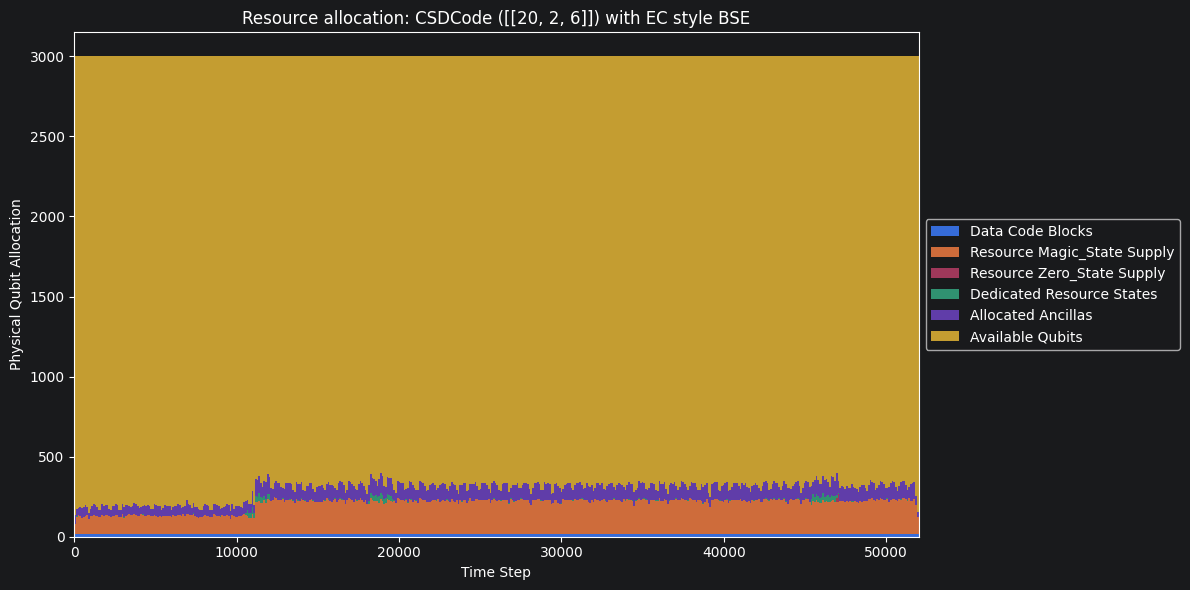

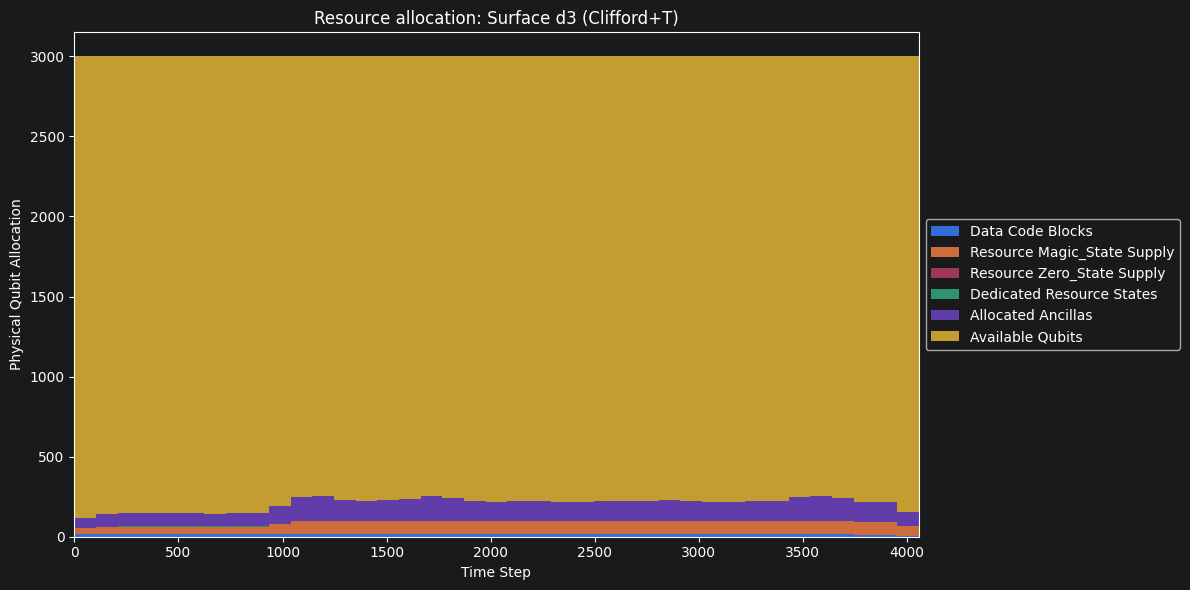

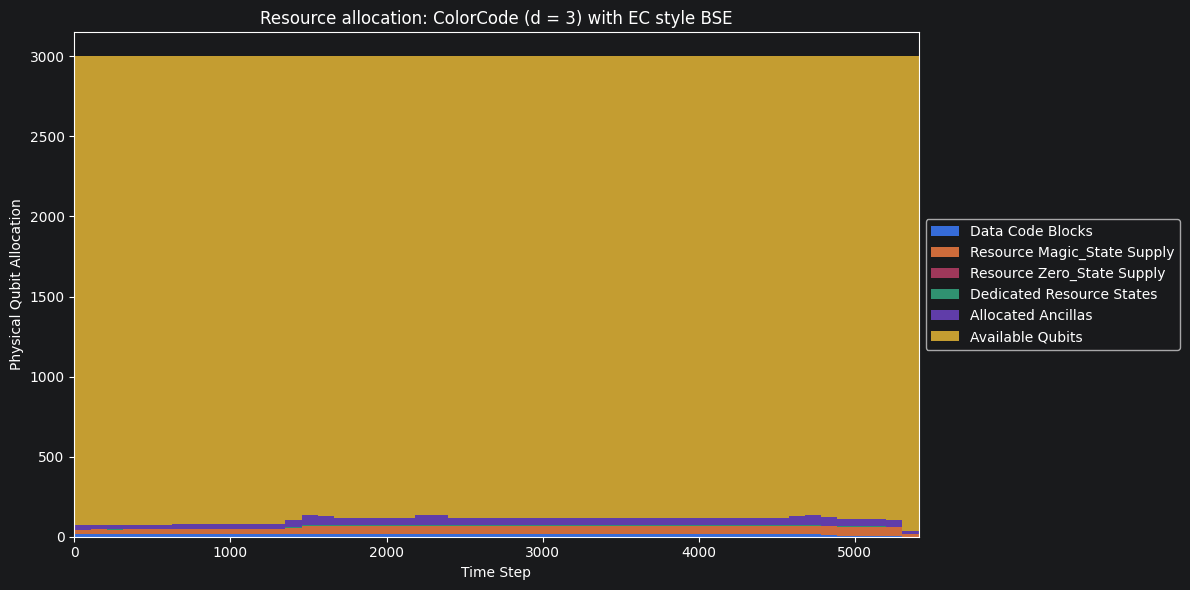

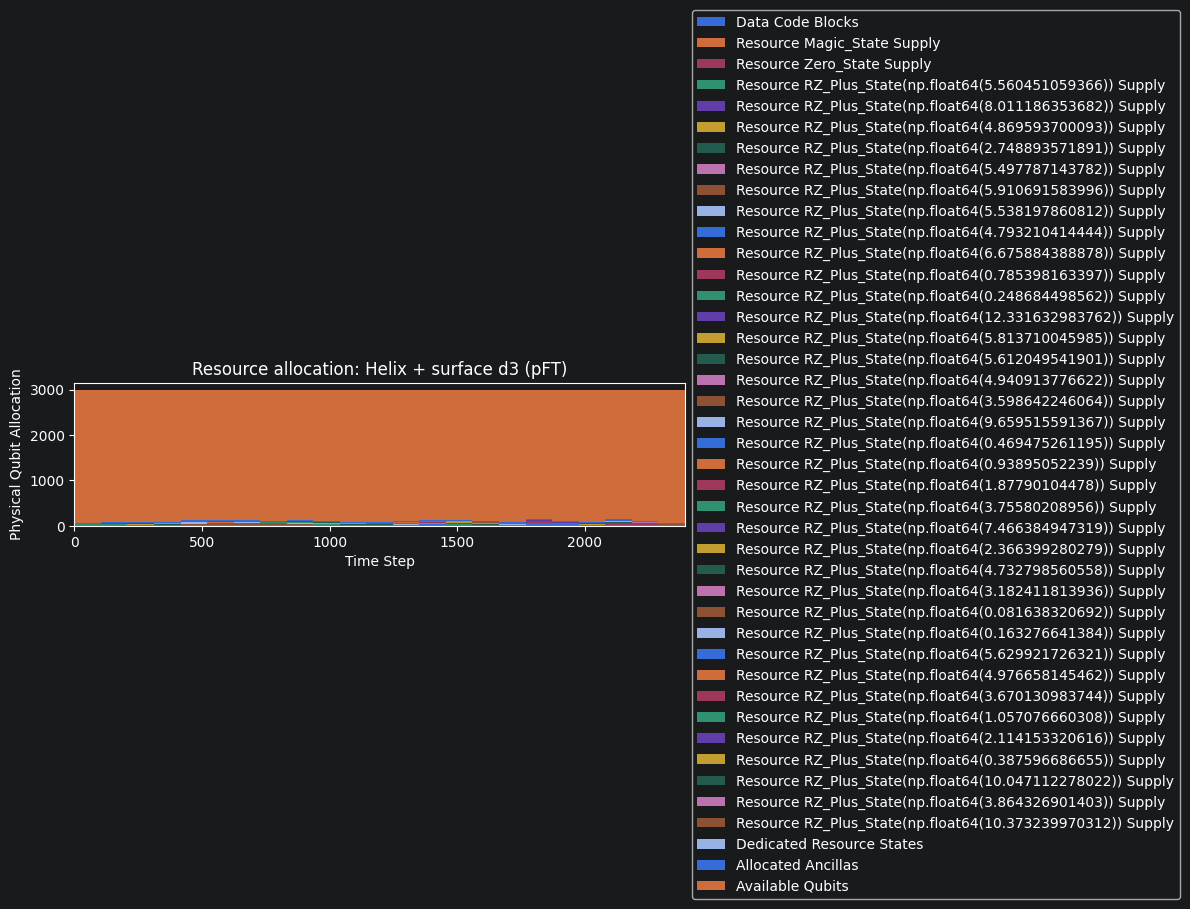

In [11]:
# Print resource allocation profiles (two options, errorbar and stacked bar)

allocation_errorbar_stride = 1000
# start = 0
# end = 20000
# Limit plotted points for the larger pickle circuit; increase for finer plots.
profile_plot_points = 500
allocation_bin_size = max(1, int(np.ceil(
    max(len(s.extrusion.time_steps) for s in schedulers) / profile_plot_points
)))
resource_state_filter = lambda state: state != CSDResourceState.ZeroECIdleState

for code, scheduler in zip(codes, schedulers):
    label = architecture_labels.get(type(code), str(code))
    title = f"Resource allocation: {label}"

    # plot_allocation_profiles_errorbar(
    #     scheduler.extrusion,
    #     title=title,
    #     stride=allocation_errorbar_stride,
    #     resource_state_filter=resource_state_filter,
    # )
    # plt.show()

    plot_allocation_profiles_stacked_bar(
        scheduler.extrusion,
        title=f"{title}",
        bin_size=allocation_bin_size,
        resource_state_filter=resource_state_filter,
        yscale = 'linear'
        # start=start,
        # end=end,
    )
    plt.show()

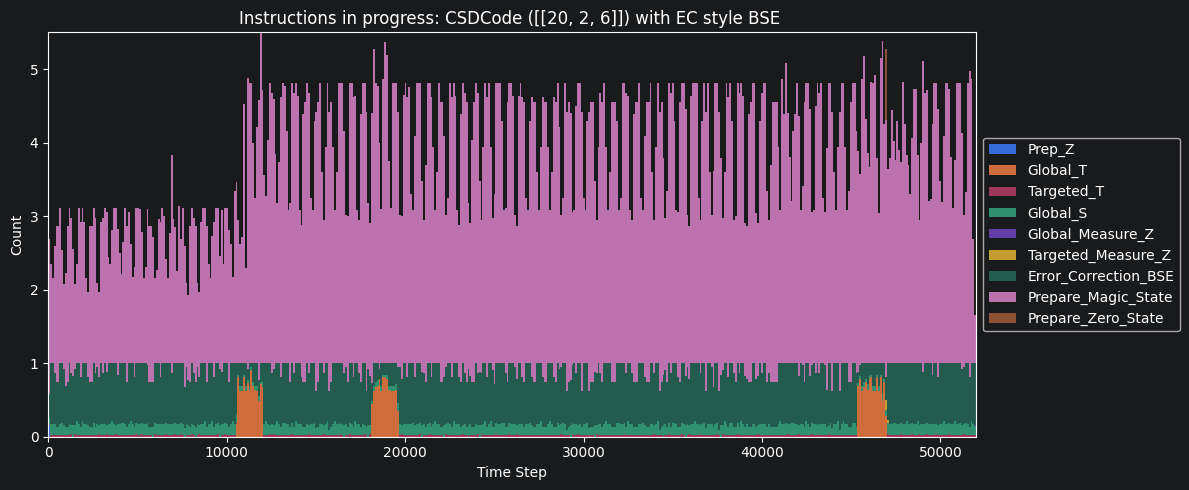

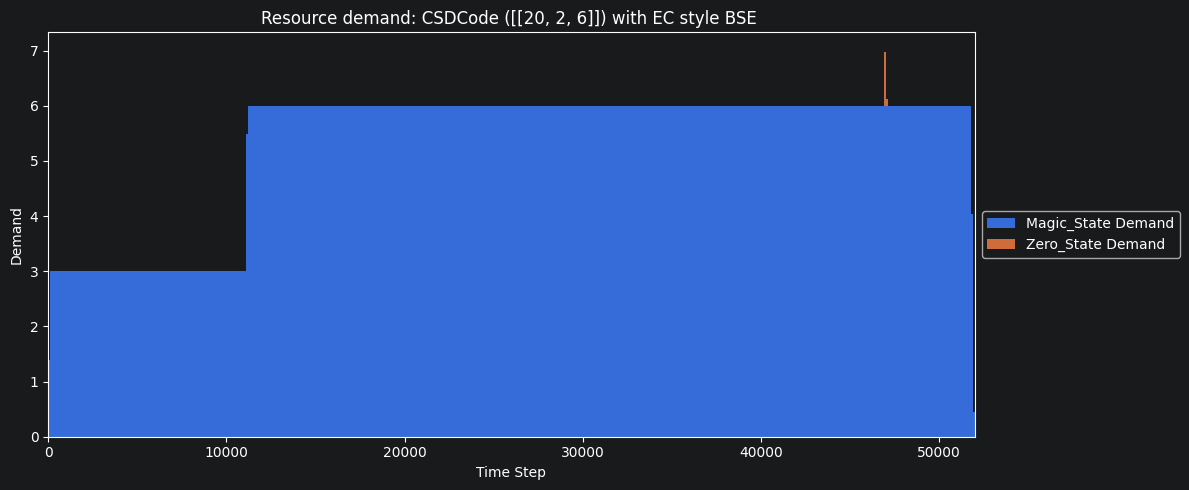

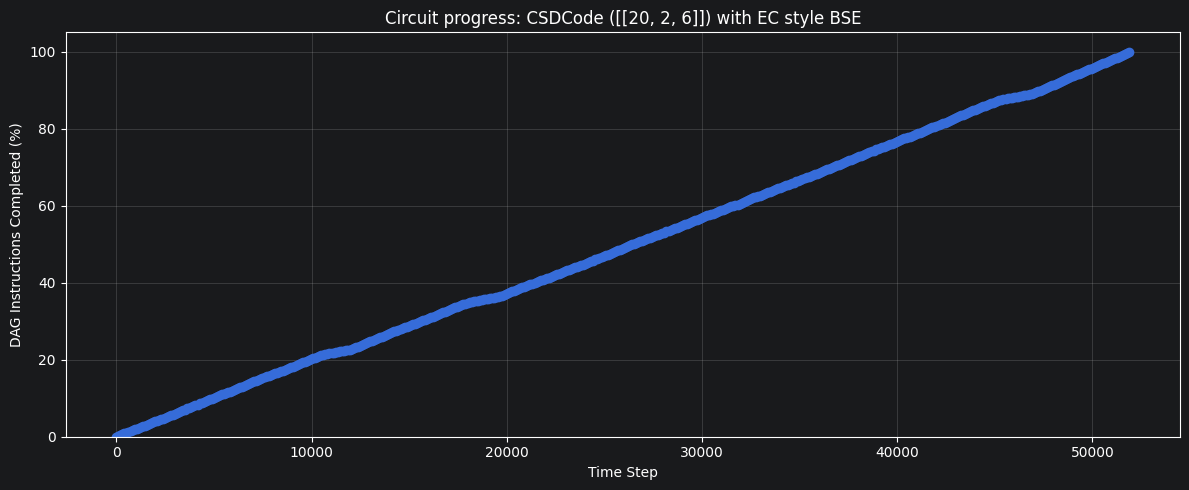

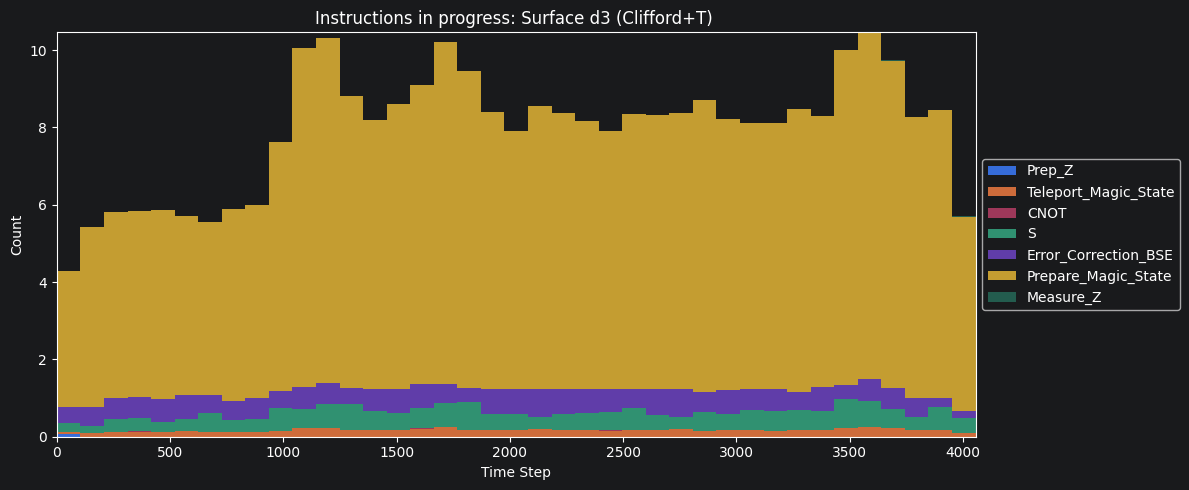

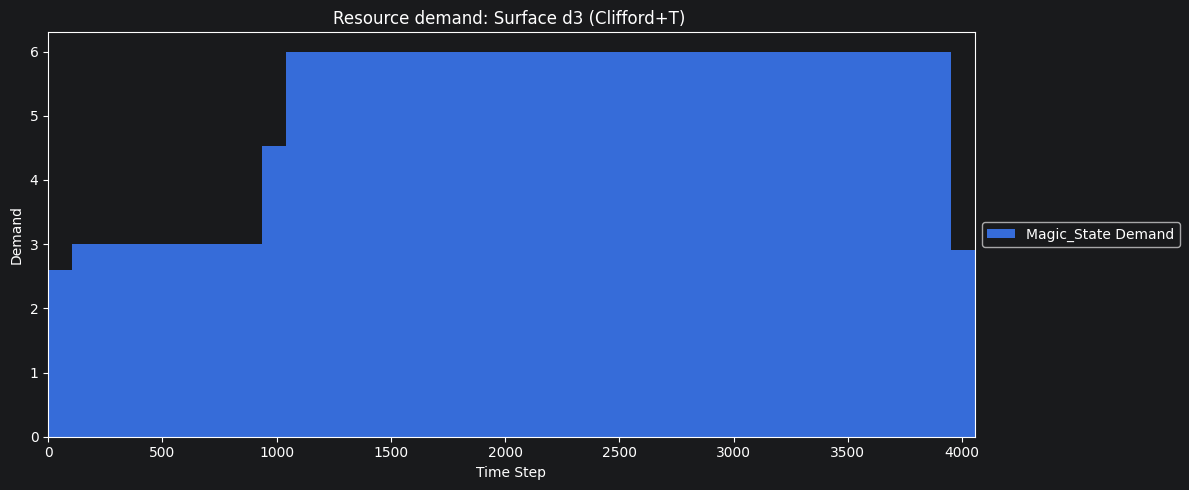

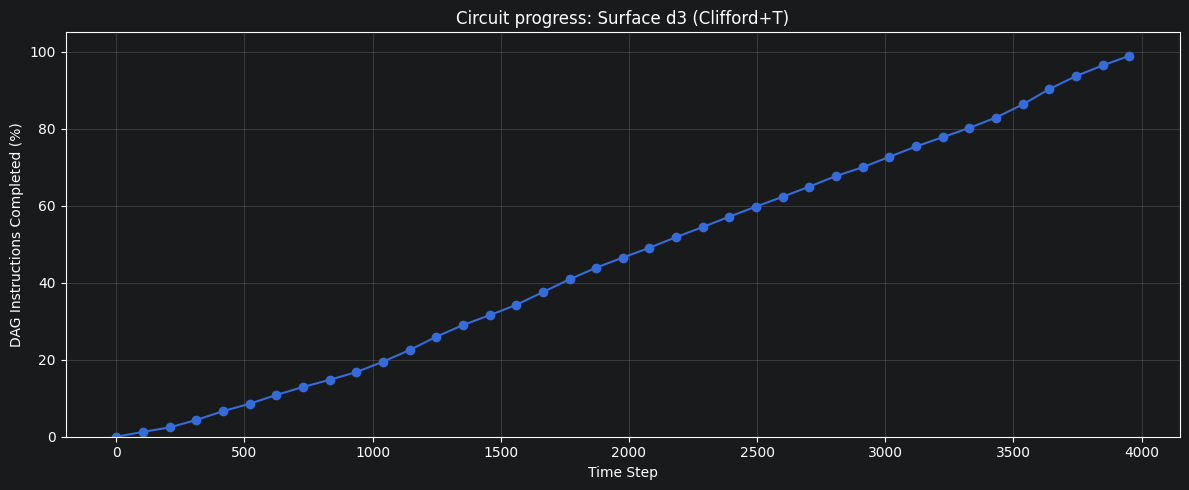

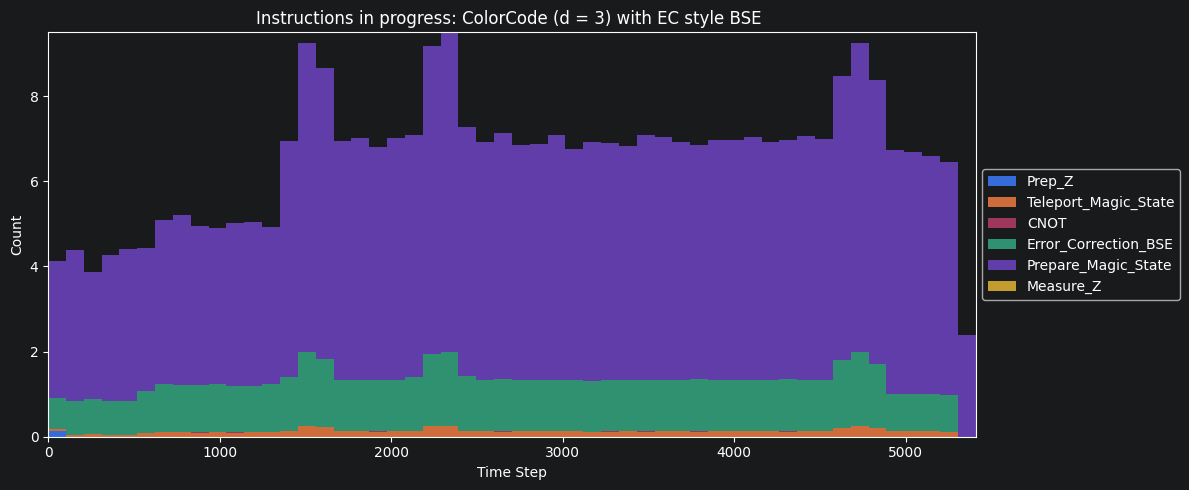

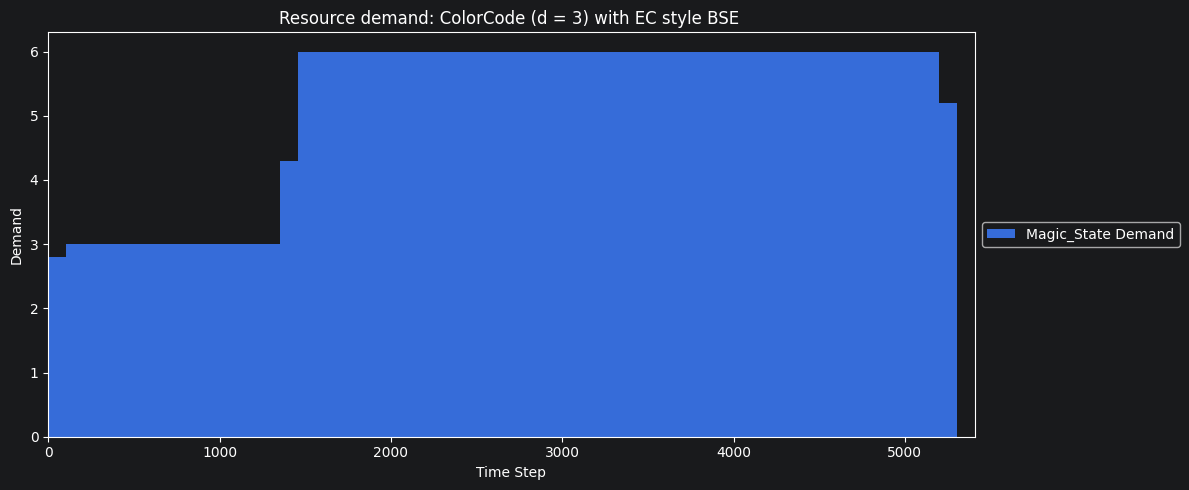

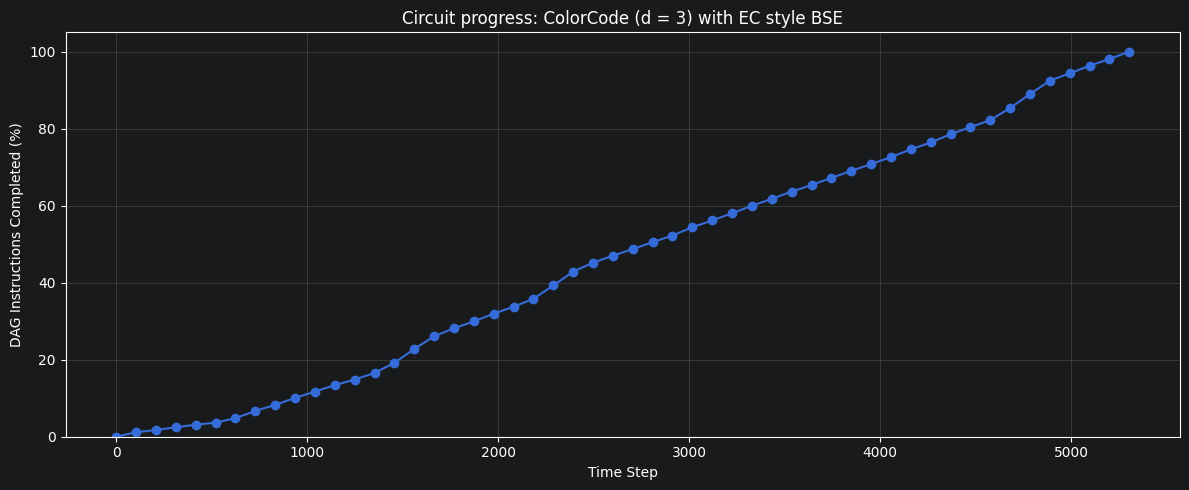

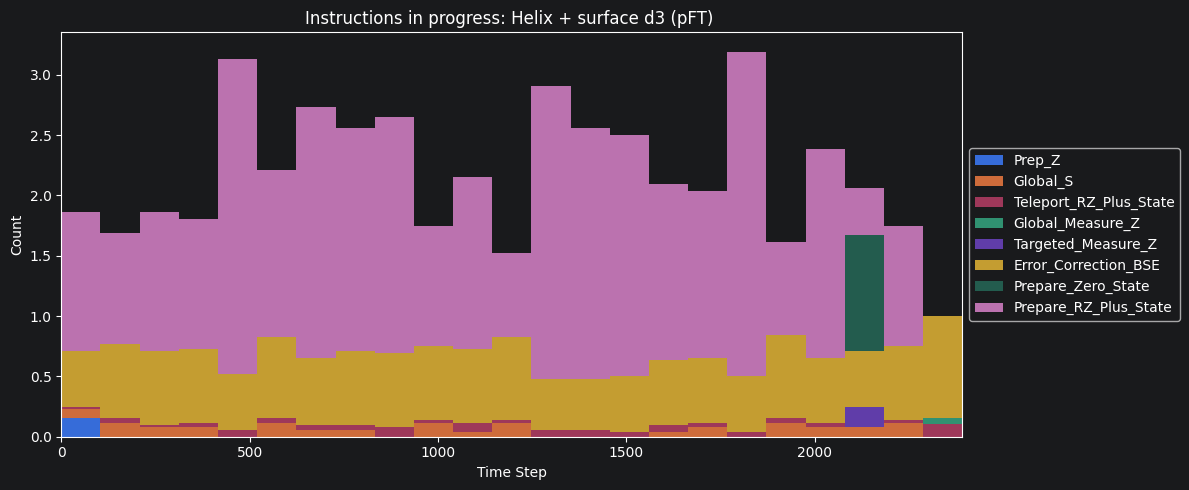

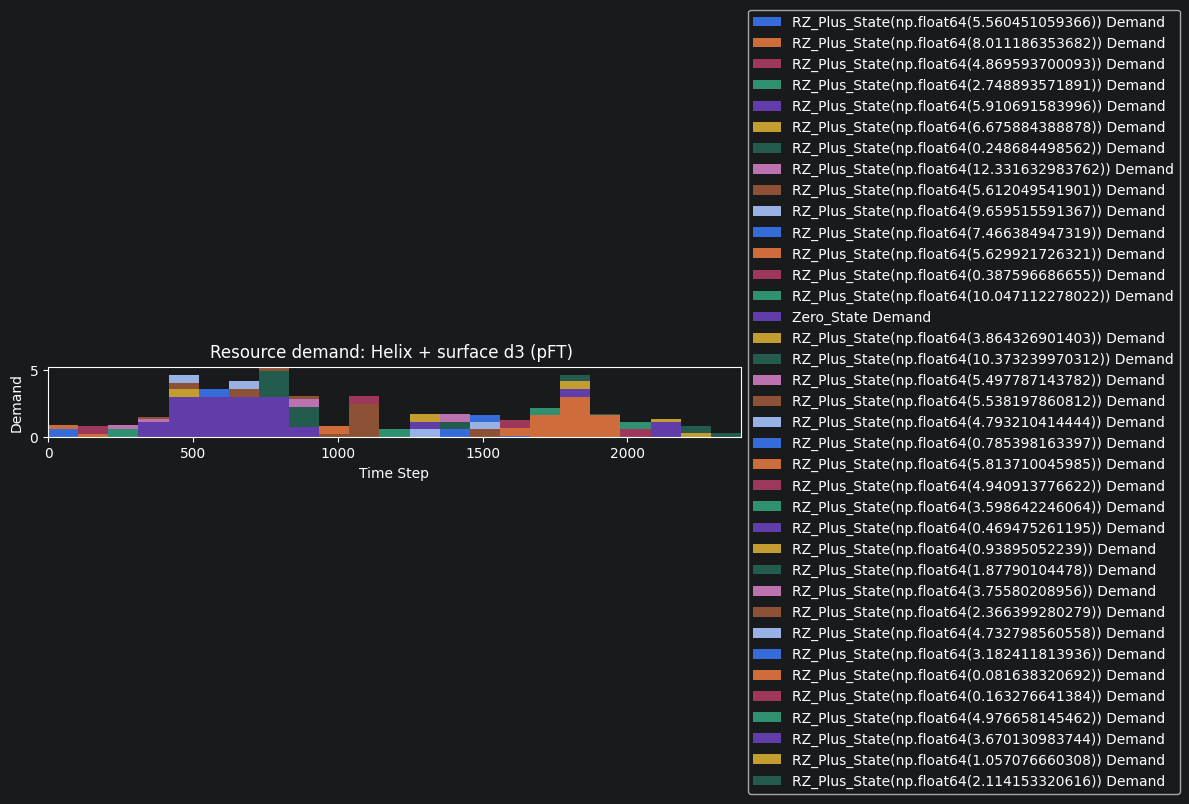

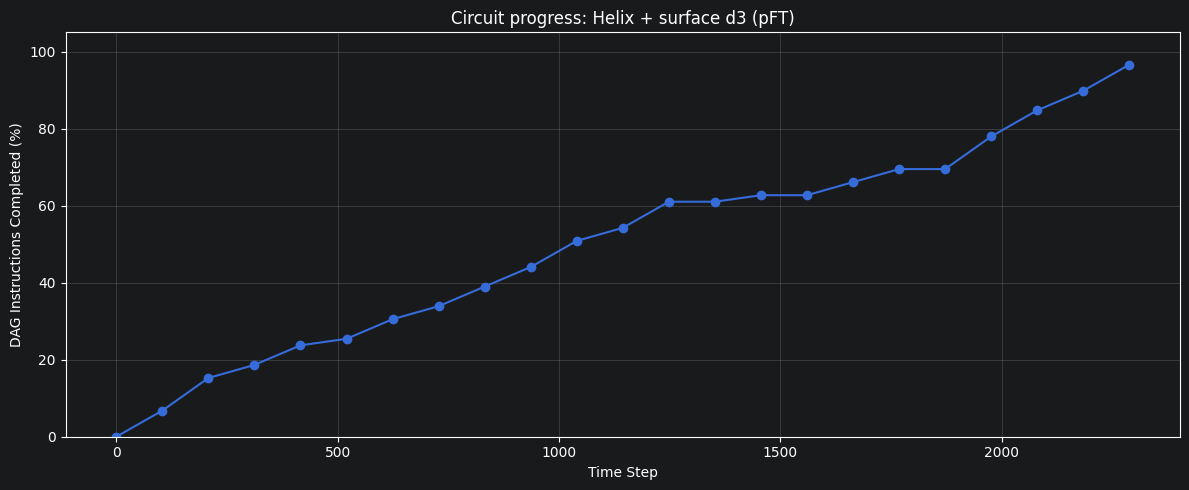

In [12]:
# Plot instructions in progress (by type) and resource state demand over time (also two options, errorbar and stacked bar)

instruction_errorbar_stride = allocation_bin_size
# start = 0
# end = 7000
instruction_bin_size = allocation_bin_size

for code, scheduler in zip(codes, schedulers):
    label = architecture_labels.get(type(code), str(code))
    # plot_instruction_profiles_errorbar(
    #     scheduler.extrusion,
    #     title=f"Instructions in progress: {label}",
    #     stride=instruction_errorbar_stride,
    #     # start=start,
    #     # end=end,
    # )
    # plt.show()

    plot_instruction_profiles_stacked_bar(
        scheduler.extrusion,
        title=f"Instructions in progress: {label} ",
        bin_size=instruction_bin_size,
        yscale='linear'
        # start=start,
        # end=end,
    )
    plt.show()

    # plot_resource_demand_errorbar(
    #     scheduler.extrusion,
    #     title=f"Resource demand: {label}",
    #     stride=instruction_errorbar_stride,
    # )
    # plt.show()

    plot_resource_demand_stacked_bar(
        scheduler.extrusion,
        title=f"Resource demand: {label} ",
        bin_size=instruction_bin_size,
        # start=start,
        # end=end,
    )
    plt.show()

    plot_dag_progress(
        scheduler.extrusion,
        title=f"Circuit progress: {label}",
        stride=instruction_errorbar_stride,
        # start=start,
        # end=end,
    )
    plt.show()